# Chapitre 4 - Cours 1 : Critères d'évaluation, capacité métier et qualité de génération

Le chapitre 3 présentait des *méthodes* d'évaluation (métriques exactes, similarité, IA
juge...). Le chapitre 4 change d'angle : on part des **critères** qui comptent pour une
application, et l'on cherche comment les mesurer. Ce premier notebook couvre la première
moitié de la section *Evaluation Criteria* du livre :

1. évaluer avant de construire (encadré *Evaluation-Driven Development*) ;
2. la capacité métier mesurée par des QCM (section *Domain-Specific Capability*) ;
3. la fragilité des QCM face au format du prompt ;
4. fluidité et cohérence, les métriques héritées de la NLG (section *Generation Capability*) ;
5. la cohérence factuelle locale vue comme de l'inférence textuelle (NLI) (section *Factual consistency*) ;
6. l'auto-vérification à la SelfCheckGPT et la vérification augmentée par la recherche ;
7. la sécurité et les classifieurs de toxicité (section *Safety*).

On travaille sur de vrais petits modèles : Qwen2.5-0.5B/1.5B-Instruct comme modèles évalués,
le classifieur NLI `DeBERTa-v3-base-mnli-fever-anli` (celui que cite le livre) et le
classifieur de toxicité RoBERTa du Skolkovo Institute.

In [1]:
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")  # modèles déjà en cache : pas d'appel réseau
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from aie.plotting import (set_style, COLORS, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY,
                          GREEN, LIGHT, annotate_bars, subtitle, finish)
from aie.diagrams import Diagram
from aie import llm
from aie import ch04_systemes as c4

set_style()
pd.set_option("display.max_colwidth", 80)
llm.seed_everything(0)

## 1. Évaluer avant de construire (section *Evaluation Criteria*)

**Le problème.** Une application déployée dont personne ne sait si elle fonctionne coûte
à maintenir, et il est difficile de décider de l'arrêter. Le livre plaide donc pour un
**développement piloté par l'évaluation** (*evaluation-driven development*), par analogie
avec le développement piloté par les tests : on écrit les critères d'évaluation **avant**
de construire. Ce n'est pas un hasard si les applications d'entreprise les plus répandues
(recommandation, détection de fraude, génération de code, classification) sont celles dont
le succès se mesure facilement.

**Quatre familles de critères.** Pour un assistant qui résume des contrats juridiques :

| Famille | Question posée | Exemple de métrique |
|---|---|---|
| capacité métier | le modèle comprend-il le droit des contrats ? | exactitude sur un QCM juridique |
| capacité de génération | le résumé est-il fidèle et cohérent ? | taux d'affirmations impliquées par le contrat (NLI) |
| suivi d'instructions | le résumé respecte-t-il le format demandé ? | taux de contraintes vérifiées (longueur, puces) |
| coût et latence | combien coûte et combien de temps prend un résumé ? | $/requête, temps jusqu'au premier token |

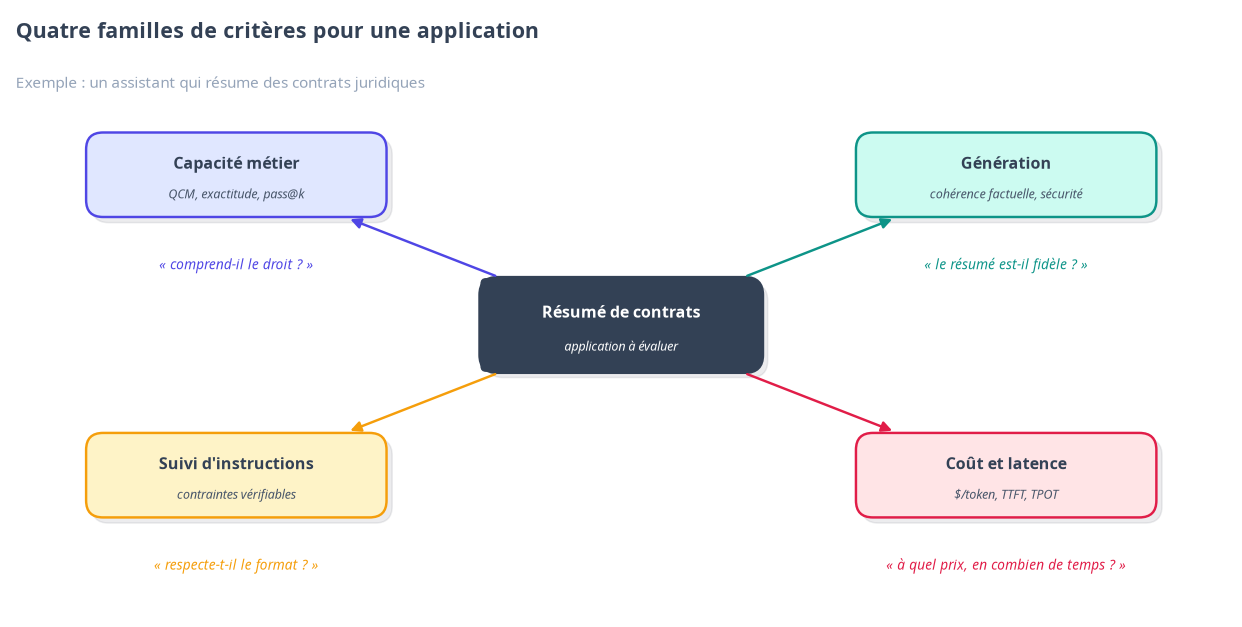

In [2]:
d = Diagram(13, 5.5, title="Quatre familles de critères pour une application",
            subtitle="Exemple : un assistant qui résume des contrats juridiques")
d.box("app", 6.5, 3.1, "Résumé de contrats", sub="application à évaluer", color=SLATE, w=3.0, h=1.0,
      kind="model", filled=True)
d.box("dom", 2.4, 4.7, "Capacité métier", sub="QCM, exactitude, pass@k", color=INDIGO, w=3.2)
d.box("gen", 10.6, 4.7, "Génération", sub="cohérence factuelle, sécurité", color=TEAL, w=3.2)
d.box("ins", 2.4, 1.5, "Suivi d'instructions", sub="contraintes vérifiables", color=AMBER, w=3.2)
d.box("cost", 10.6, 1.5, "Coût et latence", sub="$/token, TTFT, TPOT", color=ROSE, w=3.2)
for n, c in [("dom", INDIGO), ("gen", TEAL), ("ins", AMBER), ("cost", ROSE)]:
    d.arrow("app", n, color=c)
d.note(2.4, 3.75, "« comprend-il le droit ? »", color=INDIGO)
d.note(10.6, 3.75, "« le résumé est-il fidèle ? »", color=TEAL)
d.note(2.4, 0.55, "« respecte-t-il le format ? »", color=AMBER)
d.note(10.6, 0.55, "« à quel prix, en combien de temps ? »", color=ROSE)
d.show()

> **À retenir.** Une application d'IA commence par une liste de critères propres à son
> usage, rangés en quatre familles : capacité métier, génération, suivi d'instructions,
> coût et latence. Le reste du chapitre montre comment mesurer chacun.

## 2. Capacité métier : les QCM (section *Domain-Specific Capability*)

**Motivation.** La capacité métier d'un modèle est bornée par son architecture, sa taille et
ses données d'entraînement : un modèle qui n'a jamais vu de latin ne traduira pas le latin.
Pour le code, on utilise la correction fonctionnelle (chapitre 3), éventuellement complétée
par l'efficacité (BIRD-SQL compare le temps d'exécution de la requête générée à celui de la
requête de référence). Hors code, la grande majorité des benchmarks publics sont des
**questions à choix multiples** (QCM) : en avril 2024, environ 75 % des tâches de
`lm-evaluation-harness` en étaient (MMLU, AGIEval, ARC-C...).

**Pourquoi les QCM ?** Ils sont faciles à créer, à vérifier, et se comparent à une **ligne
de base aléatoire** : avec $k$ options dont une seule correcte, répondre au hasard donne
une exactitude de $1/k$ (25 % pour 4 options).

**Est-ce mieux que le hasard ?** Sur $n$ questions, le nombre de bonnes réponses d'un
devineur suit une loi binomiale $X \sim \mathcal B(n, 1/k)$. Un score $s$ n'est
significativement supérieur au hasard (au niveau 5 %) que si $P(X \ge s\,n) < 0{,}05$.

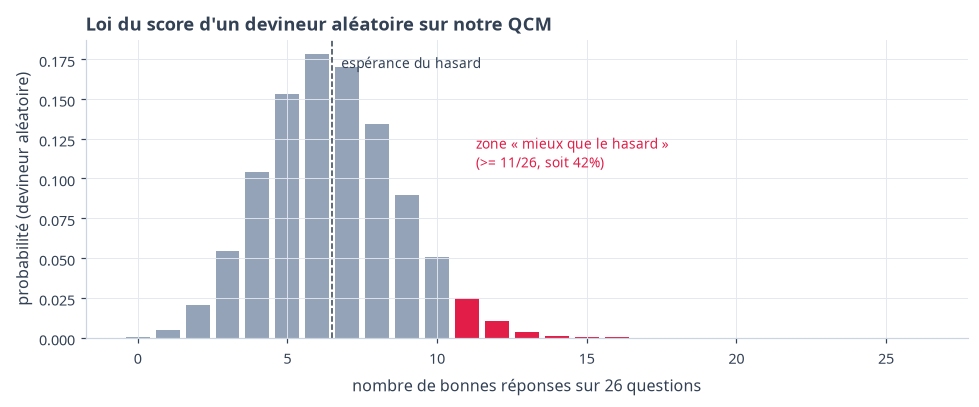

In [3]:
n_q = len(c4.MCQ_ITEMS)
ks = np.arange(n_q + 1)
pmf = np.array([c4.binom_sf(k, n_q, 0.25) - c4.binom_sf(k + 1, n_q, 0.25) for k in ks])
k_crit = next(k for k in ks if c4.binom_sf(k, n_q, 0.25) < 0.05)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(ks, pmf, color=[ROSE if k >= k_crit else GRAY for k in ks])
ax.axvline(n_q * 0.25, color=SLATE, ls="--", lw=1)
ax.text(n_q * 0.25 + 0.3, pmf.max() * 0.95, "espérance du hasard", fontsize=9)
ax.text(k_crit + 0.3, pmf.max() * 0.6, f"zone « mieux que le hasard »\n(>= {k_crit}/{n_q}, soit {k_crit/n_q:.0%})",
        color=ROSE, fontsize=9)
ax.set_xlabel(f"nombre de bonnes réponses sur {n_q} questions")
ax.set_ylabel("probabilité (devineur aléatoire)")
ax.set_title("Loi du score d'un devineur aléatoire sur notre QCM")
plt.tight_layout(); plt.show()

Notre petit QCM maison compte 26 questions réparties sur cinq domaines. On l'évalue de la
façon la plus robuste possible pour un petit modèle : plutôt que de lire le texte généré
(qui peut être « La réponse est B, car... »), on compare directement les **logits** des
quatre lettres A, B, C, D comme premier token de la réponse de l'assistant. C'est ce que
font la plupart des harnais d'évaluation, et cela exige l'accès aux logprobs (un argument
en faveur des modèles ouverts, voir le cours 3).

In [4]:
def eval_mcq(model_id, style="standard", permute=None):
    rows = []
    for i, it in enumerate(c4.MCQ_ITEMS):
        order = permute(i) if permute else None
        prompt, gold = c4.format_mcq(it, style, order)
        z = c4.letter_logits(prompt, model_id)
        p = llm.softmax(z)
        rows.append(dict(domaine=it["domaine"], gold=gold, pred=int(p.argmax()), p_pred=float(p.max()),
                         p_gold=float(p[gold])))
    df = pd.DataFrame(rows)
    df["correct"] = df.pred == df.gold
    return df

res = {"Qwen 0.5B": eval_mcq(llm.SMALL), "Qwen 1.5B": eval_mcq(llm.MEDIUM)}
llm.free_gpu()   # on libère le modèle 1,5B (le GPU est partagé)
acc = pd.DataFrame({k: v.groupby("domaine")["correct"].mean() for k, v in res.items()})
acc.loc["GLOBAL"] = [v["correct"].mean() for v in res.values()]
(acc * 100).round(0)

,Qwen 0.5B,Qwen 1.5B
domaine,,
géographie,80.0,80.0
histoire,75.0,75.0
informatique,83.0,100.0
mathématiques,50.0,100.0
sciences,40.0,100.0
GLOBAL,65.0,92.0


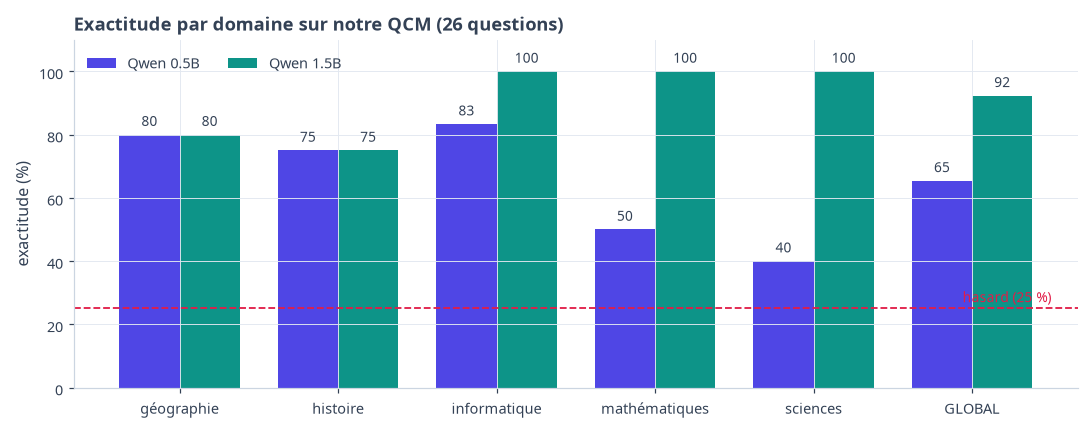

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(acc))
for j, (col, c) in enumerate(zip(acc.columns, [INDIGO, TEAL])):
    bars = ax.bar(x + (j - 0.5) * 0.38, acc[col] * 100, width=0.38, color=c, label=col)
ax.axhline(25, color=ROSE, ls="--", lw=1.2)
ax.text(len(acc) - 0.5, 27, "hasard (25 %)", color=ROSE, ha="right", fontsize=9)
ax.set_xticks(x, acc.index); ax.set_ylabel("exactitude (%)"); ax.set_ylim(0, 110)
annotate_bars(ax, "{:.0f}")
ax.set_title("Exactitude par domaine sur notre QCM (26 questions)")
ax.legend(loc="upper left", ncol=2)
plt.tight_layout(); plt.show()

Les deux modèles battent nettement le hasard, et le modèle de 1,5 milliard de paramètres
fait mieux que celui de 0,5 milliard : la taille borne la capacité métier. Attention
toutefois aux barres par domaine : avec 4 à 6 questions par domaine, une seule erreur fait
varier le score de 15 à 25 points. Nous reviendrons sur la taille d'échantillon dans le
cours 4.

Les logits donnent aussi une **confiance** : la probabilité attribuée à la lettre choisie.
Un modèle bien calibré devrait se tromper surtout quand il est peu confiant.

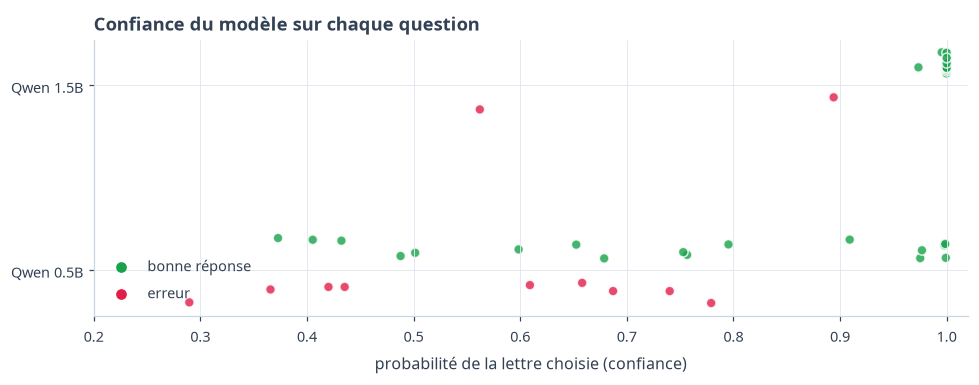

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for j, (name, df) in enumerate(res.items()):
    yj = j + np.where(df.correct, 0.12, -0.12) + np.random.default_rng(j).uniform(-0.06, 0.06, len(df))
    ax.scatter(df.p_pred, yj, c=np.where(df.correct, GREEN, ROSE), s=40, alpha=0.8, edgecolor="white")
ax.set_yticks([0, 1], list(res)); ax.set_xlabel("probabilité de la lettre choisie (confiance)")
ax.scatter([], [], c=GREEN, label="bonne réponse"); ax.scatter([], [], c=ROSE, label="erreur")
ax.legend(loc="lower left"); ax.set_xlim(0.2, 1.02)
ax.set_title("Confiance du modèle sur chaque question")
plt.tight_layout(); plt.show()

> **À retenir.** Les QCM mesurent la capacité à *reconnaître* une bonne réponse
> (classification), pas à en *générer* une. On les compare toujours à la ligne de base
> $1/k$, et l'on vérifie par la loi binomiale qu'un écart au hasard est significatif.

## 3. La fragilité des QCM face au format (section *Domain-Specific Capability*)

Le livre cite Alzahrani et al. (2024) : ajouter un espace entre la question et les options,
ou un intitulé comme « Choices: », peut suffire à changer la réponse d'un modèle. Testons
quatre présentations **sémantiquement identiques** de nos questions :

- `standard` : question, puis options ;
- `espace` : une ligne contenant une espace insérée avant les options ;
- `choix` : l'intitulé « Choix : » avant les options ;
- `inverse` : les options présentées dans l'ordre inverse (D devient A, etc.).

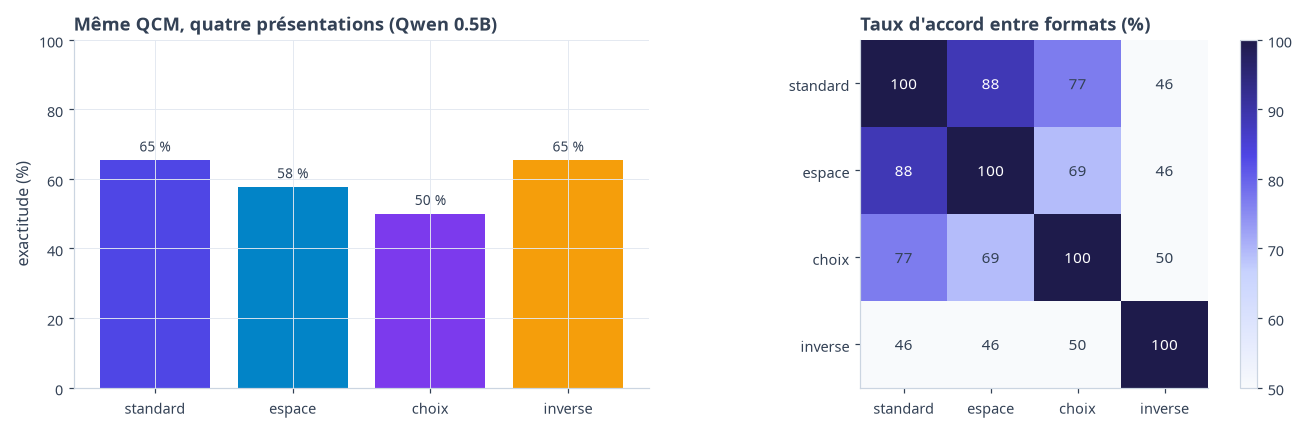

In [7]:
formats = {
    "standard": dict(style="standard"),
    "espace": dict(style="espace"),
    "choix": dict(style="choix"),
    "inverse": dict(style="standard", permute=lambda i: [3, 2, 1, 0]),
}
fmt_res = {f: eval_mcq(llm.SMALL, **kw) for f, kw in formats.items()}

# la réponse choisie, exprimée comme indice de l'option d'origine (pour comparer les formats)
def chosen_option(df, fmt):
    if fmt == "inverse":
        return 3 - df.pred
    return df.pred

chosen = pd.DataFrame({f: chosen_option(df, f) for f, df in fmt_res.items()})
agree = pd.DataFrame([[(chosen[a] == chosen[b]).mean() for b in chosen] for a in chosen],
                     index=chosen.columns, columns=chosen.columns)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw=dict(width_ratios=[1, 1.1]))
accs = [df.correct.mean() * 100 for df in fmt_res.values()]
axes[0].bar(list(fmt_res), accs, color=[INDIGO, SKY, VIOLET, AMBER])
annotate_bars(axes[0], "{:.0f} %")
axes[0].set_ylabel("exactitude (%)"); axes[0].set_ylim(0, 100)
axes[0].set_title("Même QCM, quatre présentations (Qwen 0.5B)")
im = axes[1].imshow(agree.values * 100, cmap="aie_seq", vmin=50, vmax=100)
axes[1].set_xticks(range(4), agree.columns); axes[1].set_yticks(range(4), agree.index)
axes[1].grid(False)
for i in range(4):
    for j in range(4):
        v = agree.values[i, j] * 100
        axes[1].text(j, i, f"{v:.0f}", ha="center", va="center", color="white" if v > 80 else SLATE)
axes[1].set_title("Taux d'accord entre formats (%)")
plt.colorbar(im, ax=axes[1], fraction=0.046)
finish(fig)

Des changements que personne ne jugerait significatifs modifient à la fois l'exactitude et
une part importante des réponses individuelles. Deux conséquences pratiques :

1. un score de benchmark n'a de sens qu'avec **son gabarit de prompt exact** ; comparer deux
   modèles évalués avec des gabarits différents est risqué ;
2. pour une évaluation plus robuste, on peut moyenner sur plusieurs présentations, ou exiger
   qu'une question soit réussie sous **toutes** les permutations des options (exercice 4.1).

Un autre biais classique est le **biais de position** : la distribution des lettres prédites
n'est pas uniforme, alors que nos bonnes réponses sont réparties sur A, B, C, D.

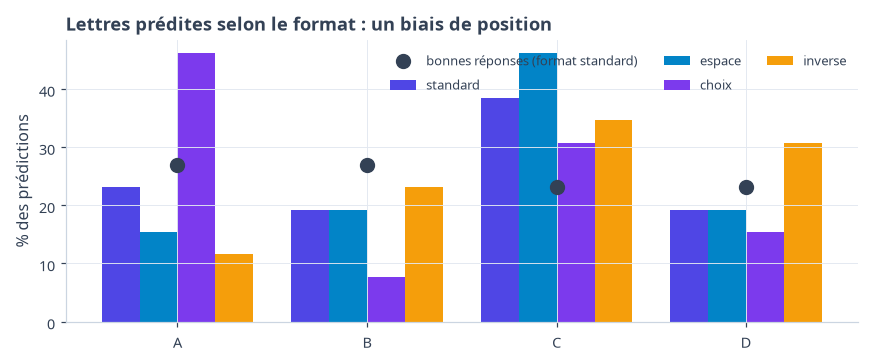

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.4))
w = 0.2
for j, (f, df) in enumerate(fmt_res.items()):
    counts = np.bincount(df.pred, minlength=4) / len(df) * 100
    ax.bar(np.arange(4) + (j - 1.5) * w, counts, width=w, color=[INDIGO, SKY, VIOLET, AMBER][j], label=f)
gold_counts = np.bincount(fmt_res["standard"].gold, minlength=4) / n_q * 100
ax.plot(np.arange(4), gold_counts, "o", color=SLATE, ms=9, label="bonnes réponses (format standard)")
ax.set_xticks(range(4), list("ABCD")); ax.set_ylabel("% des prédictions")
ax.set_title("Lettres prédites selon le format : un biais de position")
ax.legend(ncol=3, fontsize=8.5, loc="upper right")
plt.tight_layout(); plt.show()

> **À retenir.** Un score de QCM dépend du gabarit : espaces, intitulés et ordre des options
> peuvent changer une fraction notable des réponses. Fixez et publiez le gabarit, et mesurez
> la stabilité de votre évaluation sous de petites perturbations.